# The argument, step by step — Step 1: the world where it works

First notebook of a stepwise series. This step builds the **clean world** — no intrinsic red
noise, no gravitational-wave background, no source-on-source confusion (every comb at $s=1$) —
and shows the folklore being **true** in it: as the array's sensitivity grows, sources are
detected, their combs sharpen, and the pulsar's distance certifies against an honest
false-alarm threshold.

Later steps re-run **this exact pipeline** with one honest ingredient switched on at a time.
The machinery is built for that: a single `WORLD` dict of toggles, and every experiment takes
the world as an argument.

**Provenance.** Standalone: numpy/scipy/matplotlib + **hasasia 1.2.3** (sensitivity curves);
fixed seeds; population construction, the fixed-pulsar convention ($\sigma_d=2$ pc), the
null-measured certification bar, and the measured-$K$ method (participation ratio over null
winners, the estimator validated in the six-worlds notebook) are carried over from there. The source population is the campaign's V1 sky (NG15 full physics), ported
verbatim in section 1b — nothing about the sky is tuned; the only pedagogical dial is the
fixed pulsar's own timing noise.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
import hasasia, hasasia.sim as hsim, hasasia.sensitivity as hsen
np.seterr(all="ignore")
plt.rcParams.update({"figure.dpi":110,"font.size":9,"axes.spines.top":False,
                     "axes.spines.right":False,"legend.frameon":False})
BLUE, RED, INK = "#2b5aa0", "#a03030", "0.35"
print("hasasia", hasasia.__version__)

PARAMS=dict(SEED=20260821, L_TRUE=1.42, SIGMA_D=2.0,
            N_PSR=120, SIGMA_TOA=100e-9, SIGMA_PSR=450e-9, CAD_D=14.0,
            SPANS=(5,10,15,20,25), RHO_DET=5.0, NSRC=3000,
            F_POP=(1e-9,3.0e-7), NREAL=200,
            C_PC_S=2.99792458e8/3.0856775814913673e16, YR_S=365.25*86400.0)
P=PARAMS; TOOTH=0.25
WORLD=dict(red_noise=False, gwb=False, confusion=False, loudness_structure=False)
print("WORLD toggles:", WORLD)

rng0=np.random.default_rng(P["SEED"])
freqs=np.logspace(np.log10(6e-10),-7,120)
_r=np.random.default_rng(42)
_phi=_r.uniform(0,2*np.pi,P["N_PSR"]); _th=np.arccos(_r.uniform(-1,1,P["N_PSR"]))
_CURVES={}
def curve(T):
    if T not in _CURVES:
        ps=hsim.sim_pta(timespan=float(T),cad=365.25/P["CAD_D"],sigma=P["SIGMA_TOA"],
                        phi=_phi,theta=_th,A_gwb=0,freqs=freqs)
        _CURVES[T]=hsen.DeterSensitivityCurve(
            [hsen.Spectrum(p,freqs=freqs) for p in ps]).h_c
    return _CURVES[T]

# ---- Faithful standalone port of active_wheel_demo_v4 cell 3 (V1): the NG15
# full-physics joint (Mc,z) population, ABSOLUTE normalisation, discrete tail.
G_SI,C_SI=6.674e-11,2.998e8
MSUN,MPC=1.989e30,3.086e22
YRV=3.15576e7
T_YR=30; T_OBS=T_YR*YRV; F_YR=1/YRV
ALPHA_F=-8/3; F_RANGE=(2e-10,1e-7); F_BEND=2e-9; MC_MIN=1e8*MSUN
A_NG15=6.4e-15; RATE_RESIDUAL=2.47
NG_PSI0,NG_MPSI0,NG_MU,NG_EPS=-2.0,11.4,8.60,0.30
NG_APSI0,NG_AMU,NG_FBULGE=-1.21,1.10,0.615
NG_P0,NG_BETP=0.033,1.0
NG_T0GYR,NG_BETT,NG_GAMT=0.5,-0.5,-1.0
NG_PSIZ,NG_MPSIZ,NG_APSIZ=-0.60,0.11,-0.03
KH=(8/np.sqrt(10))*G_SI**(5/3)*np.pi**(2/3)/C_SI**4
freqsV=np.logspace(np.log10(F_RANGE[0]),-7,100)
H0_SI=69.33*1e3/MPC
_zg=np.linspace(0,3.0,3001)
_Ez=np.sqrt(0.228*(1+_zg)**3+0.772)
_dcg=np.concatenate([[0],np.cumsum((C_SI/H0_SI)*0.5*(1/_Ez[1:]+1/_Ez[:-1])*np.diff(_zg))])
def d_com_m(z): return np.interp(z,_zg,_dcg)
def dt_dz(z): return 1.0/((1+z)*H0_SI*np.interp(z,_zg,_Ez))
_rngJ=np.random.default_rng(1234)
_lm1=np.linspace(9.5,13.2,190); _qs=np.linspace(0.25,1.0,26); _zs=np.linspace(0.02,2.0,55)
_LM1,_QS,_ZS=np.meshgrid(_lm1,_qs,_zs,indexing="ij")
_dlm,_dq,_dz=_lm1[1]-_lm1[0],_qs[1]-_qs[0],_zs[1]-_zs[0]
_Psi=np.log(10)*10**(NG_PSI0+NG_PSIZ*_ZS) \
     *(10**_LM1/10**(NG_MPSI0+NG_MPSIZ*_ZS))**(1+NG_APSI0+NG_APSIZ*_ZS) \
     *np.exp(-10**_LM1/10**(NG_MPSI0+NG_MPSIZ*_ZS))
_Pp=NG_P0*(1+_ZS)**NG_BETP
_Tg=NG_T0GYR*1e9*YRV*(1+_ZS)**NG_BETT*_QS**NG_GAMT
_eta=_Psi*_dlm*(_Pp/_Tg)*dt_dz(_ZS)*_dz*_dq
_kp=_eta>0
_LM1,_QS,_ZS,_eta=_LM1[_kp],_QS[_kp],_ZS[_kp],_eta[_kp]
_NSC=16
_LM1=np.repeat(_LM1,_NSC); _QS=np.repeat(_QS,_NSC); _ZS=np.repeat(_ZS,_NSC)
_eta=np.repeat(_eta/_NSC,_NSC)
_M1=10**(NG_MU+NG_AMU*np.log10(NG_FBULGE*10**_LM1/1e11)+_rngJ.normal(0,NG_EPS,_LM1.shape))
_qbh=_QS**NG_AMU
SRC_MC=(_M1*(_M1*_qbh))**0.6/(_M1*(1+_qbh))**0.2*MSUN
_kp=SRC_MC>=MC_MIN
SRC_MC=SRC_MC[_kp]; SRC_Z=_ZS[_kp]; _eta=_eta[_kp]
_dc_m=d_com_m(SRC_Z); SRC_DL=(1+SRC_Z)*_dc_m
_Ctau=(5/96)*(G_SI*SRC_MC/C_SI**3)**(-5/3)*np.pi**(-8/3)
_shell=4*np.pi*(C_SI/MPC)*(1+SRC_Z)*(_dc_m/MPC)**2
SRC_W=RATE_RESIDUAL*_eta*_Ctau*(1+SRC_Z)**(-8/3)*_shell
SRC_AMP=KH*(SRC_MC*(1+SRC_Z))**(5/3)/SRC_DL
bin_edges=np.arange(F_RANGE[0],F_RANGE[1],1/T_OBS)
bin_cent=0.5*(bin_edges[1:]+bin_edges[:-1])
n_per_bin=SRC_W.sum()*np.maximum(bin_cent,F_BEND)**ALPHA_F/(bin_cent*T_OBS)
_ordA=np.argsort(SRC_AMP); _ampS=SRC_AMP[_ordA]
_cwS=np.cumsum(SRC_W[_ordA]); _cwT=_cwS[-1]
# split & UL curves (V1 recipe: 200-psr deepest bar/10; H95 anchored shape)
def _raw(n,s,t,A,seed=42,cad=26):
    r=np.random.default_rng(seed)
    ps=hsim.sim_pta(timespan=t,cad=cad,sigma=s*1e-9,phi=r.uniform(0,2*np.pi,n),
                    theta=np.arccos(r.uniform(-1,1,n)),A_gwb=A,freqs=freqsV)
    return hsen.DeterSensitivityCurve([hsen.Spectrum(p,freqs=freqsV) for p in ps]).h_c
SNR_BAR=3.0
def det_curve(hc,bar=SNR_BAR): return bar*hc/np.sqrt(freqsV*T_OBS)
H_SPLIT=det_curve(_raw(200,100.0,T_YR,A_NG15))*10**(-0.5)/10.0
def h_split_of_f(f): return np.interp(f,freqsV,H_SPLIT)
_shape=_raw(67,100.0,15.0,A_NG15)/np.sqrt(freqsV*15*YRV)
H95=_shape*(8.0e-15/np.interp(6e-9,freqsV,_shape))
def h95_of_f(f): return np.interp(f,freqsV,H95)
def draw_population(seed=3):
    rng=np.random.default_rng(seed)
    hs=h_split_of_f(bin_cent)
    F,H,MCx=[],[],[]
    for k,fc in enumerate(bin_cent):
        amp_cut=hs[k]/fc**(2/3)
        j=np.searchsorted(_ampS,amp_cut)
        w_below=_cwS[j-1] if j>0 else 0.0
        p_above=1.0-w_below/_cwT
        n=rng.poisson(n_per_bin[k]*p_above)
        if n==0 or j>=len(_ampS): continue
        def _d(m):
            u=rng.uniform(w_below,_cwT,m); ii=_ordA[np.searchsorted(_cwS,u)]
            return ii, fc+(rng.uniform(0,1,m)-0.5)/T_OBS
        ii,fss=_d(n); hh=SRC_AMP[ii]*fss**(2/3)
        for _ in range(50):
            bad=hh>h95_of_f(fss)
            if not bad.any(): break
            i2,f2=_d(int(bad.sum())); ii[bad],fss[bad]=i2,f2
            hh[bad]=SRC_AMP[i2]*f2**(2/3)
        F.append(fss);H.append(hh);MCx.append(SRC_MC[ii])
    return np.concatenate(F),np.concatenate(H),np.concatenate(MCx)
f_src,h_src,mc_src=draw_population(3)
f_E,h_E=f_src,h_src
Mc=mc_src/MSUN
P["NSRC"]=len(f_E)
print(f"V1 population ported verbatim: {len(f_E):,} discrete sources above the split")
print(f"  (fidelity check: the frozen campaign notebook draws exactly 18,727)")

def rho_E(T):        # Earth-term ARRAY SNR (Hazboun+19 Eq. 79 convention)
    hc=curve(T)
    return (h_E/np.interp(f_E,freqs,hc))*np.sqrt(f_E*T*P["YR_S"])
def detected(T): return rho_E(T)>=P["RHO_DET"]

# the fixed pulsar: mu per source drawn once (fixed geometry); its timing noise
# is SIGMA_PSR -- detection uses the WHOLE array's best pulsars, ranging uses THIS one.
mu=np.arccos(np.random.default_rng(5000).uniform(-0.9,0.9,P["NSRC"]))
kap_all=2*np.pi*f_E*(1-np.cos(mu))/P["C_PC_S"]
GRID=np.linspace(-3*P["SIGMA_D"],3*P["SIGMA_D"],1601)
NMAX_COMB=30      # inventory cap: detection finds hundreds; only the strongest
                  # are usable rulers (the campaign machine's nmax, same logic)
print(f"fixed pulsar: sigma_d = {P['SIGMA_D']} pc, timing noise {P['SIGMA_PSR']*1e9:.0f} ns")
print(f"K is MEASURED per span below (participation ratio over null winners --")
print(f"the r4-adopted method; with a mixed coarse+fine inventory the coarsest-comb")
print(f"convention is no longer meaningful and is not used)")
print(f"detected at 25 yr: {int(detected(25).sum())} of {P['NSRC']} sources")

hasasia 1.2.3
WORLD toggles: {'red_noise': False, 'gwb': False, 'confusion': False, 'loudness_structure': False}


V1 population ported verbatim: 18,727 discrete sources above the split
  (fidelity check: the frozen campaign notebook draws exactly 18,727)
fixed pulsar: sigma_d = 2.0 pc, timing noise 450 ns
K is MEASURED per span below (participation ratio over null winners --
the r4-adopted method; with a mixed coarse+fine inventory the coarsest-comb
convention is no longer meaningful and is not used)


detected at 25 yr: 5110 of 18727 sources


## 1 — The instrument, growing

The array: 120 pulsars, 100 ns white-noise timing, fortnightly cadence, standard timing model,
built in hasasia. Below, its **deterministic-source sensitivity curve** — hasasia's $h_c$ for
individual (continuous-wave) sources, the strain at which such a source reaches unit SNR after
the timing-model fit — at five observing spans.

**Why the curve improves with span:** more cycles accumulate ($\rho\propto\sqrt{T}$ at fixed
strain), lower frequencies become reachable (the wall at $1/T$ moves left), and each frequency
element narrows ($1/T$ binning).

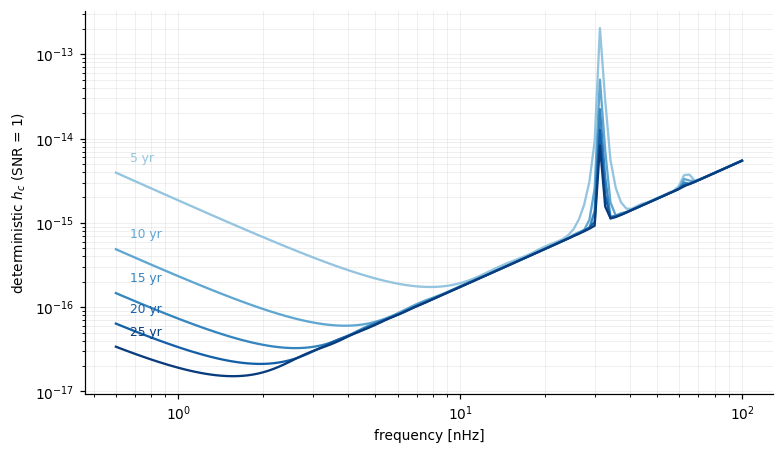

In [2]:
fig,ax=plt.subplots(figsize=(7.2,4.2))
shades=plt.cm.Blues(np.linspace(0.4,0.95,len(P["SPANS"])))
for T,col in zip(P["SPANS"],shades):
    ax.loglog(freqs*1e9,curve(T),color=col,lw=1.5)
    ax.text(freqs[0]*1e9*1.12,curve(T)[0]*1.25,f"{T} yr",fontsize=8,color=col,
            va="bottom",ha="left")
ax.set_xlabel("frequency [nHz]"); ax.set_ylabel(r"deterministic $h_c$ (SNR = 1)")
ax.grid(alpha=.25,lw=.5,which="both")
plt.tight_layout(); plt.show()

**Figure 1.** The 120-pulsar array's deterministic-source sensitivity at 5–25 yr spans
(hasasia `DeterSensitivityCurve`; SNR $=(h/h_c)\sqrt{fT}$, Hazboun et al. 2019 Eq. 79). The
family deepens and extends to lower frequency as the span grows.

## 1b — The simulated sky behind everything

Before laying the population against the curves, look at the population itself — presented the
way the campaign's V1 section presents its own (`wheel_demo_v4.ipynb`, the NG15 full-physics
hybrid).

**What this sky is: the campaign's V1 population, ported verbatim.** The NANOGrav-15yr
full-physics joint $(M_c,z)$ realisation — GSMF × $M$–$\sigma$ machinery at the paper's Table-B1
fiducials, **absolute normalisation** from its merger rate (with V1's stated ×2.47 rate
residual), the GW-driven $f^{-8/3}$ occupancy with the 2 nHz environmental bend, the hybrid
split against a 200-pulsar deepest-bar curve, and rejection above the published CW 95 % upper
limit. Same constants, same seeds; the fidelity check below reproduces the frozen notebook's
draw exactly: **18,727 discrete sources**.

**The one deliberate difference:** V1 also carries an **analytic faint sea** — the unresolvable
remainder below the split, never drawn, unsubtractable. It is *omitted* here, and that omission
is not a simplification of convenience: **the absence of the sea is the definition of world 1.**
It returns in **step 2**, with the `gwb` toggle.

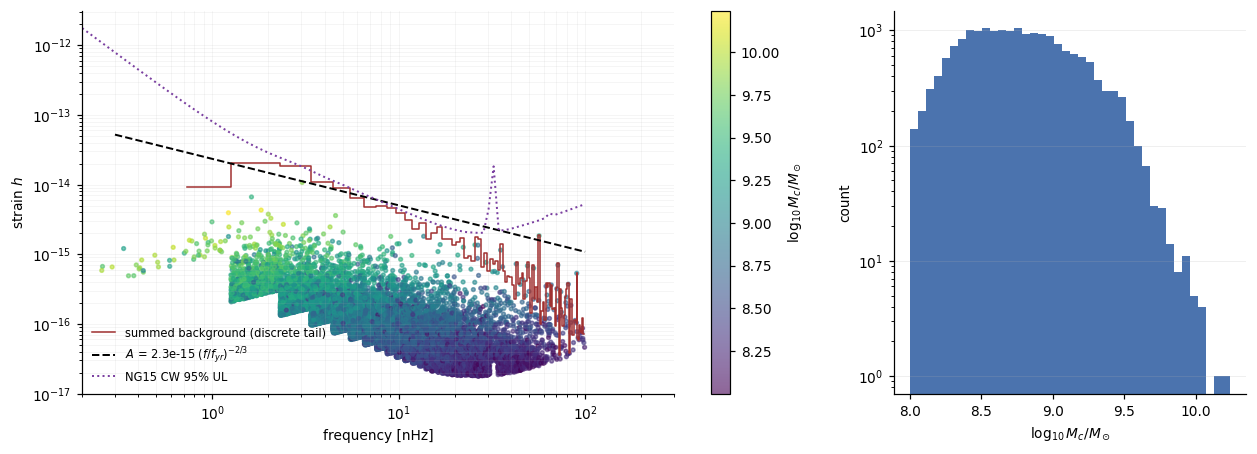

18,727 discrete sources; the analytic FAINT SEA of V1 is computed there
but OMITTED here -- that omission is the clean world's definition
fitted background amplitude of the discrete tail alone: A = 2.33e-15
  (NG15 total: 6.4e-15 -- the deficit is the sea's share plus realisation)
sources above the NG15 CW 95% upper limit: 0  (0 by construction -- V1's reject-and-redraw is ported too)

WHAT WOULD THE FAINT SEA DO AT THIS LEVEL?  (measured: the same 120-psr,
25-yr detection curve with an NG15-amplitude background switched on)
   at    3 nHz: detection threshold x107.11 worse
   at   10 nHz: detection threshold x8.38 worse
   at   30 nHz: detection threshold x1.29 worse
   detected at 25 yr, rho_E >= 5: 5110 sources clean vs 5 with the sea on
   -> at low frequency the sea is ALREADY the limiting noise for detection;
      in this world it is set to zero, which is part of what makes the world clean.
      This single toggle IS the gap between step 1 and the campaign notebook,
      whose

In [3]:
# background summed in V1's own 1/T bins (T = 30 yr, the campaign grid)
Pbin=np.zeros(len(bin_cent))
bi=np.clip(np.digitize(f_E,bin_edges)-1,0,len(bin_cent)-1)
np.add.at(Pbin,bi,h_E**2)
hc_bg=np.sqrt(Pbin)
F_YRc=1.0/P["YR_S"]
m=(Pbin>0)&(bin_cent<1e-8)&(bin_cent>=max(1/T_OBS,F_BEND))
A_TOY=float(np.exp(np.mean(np.log(hc_bg[m])+(2/3)*np.log(bin_cent[m]/F_YRc))))
viol=int((h_E>h95_of_f(f_E)).sum())
_psea=hsim.sim_pta(timespan=25.0,cad=365.25/P["CAD_D"],sigma=P["SIGMA_TOA"],
                   phi=_phi,theta=_th,A_gwb=6.4e-15,freqs=freqs)
hc_sea=hsen.DeterSensitivityCurve(
    [hsen.Spectrum(p,freqs=freqs) for p in _psea]).h_c
hc_clean=curve(25)
fig,ax=plt.subplots(1,2,figsize=(11.5,4.2),gridspec_kw={"width_ratios":[2.1,1]})
sc=ax[0].scatter(f_E*1e9,h_E,c=np.log10(Mc),s=6,cmap="viridis",alpha=.6,rasterized=True)
ax[0].plot(bin_cent[Pbin>0]*1e9,hc_bg[Pbin>0],color="#a03030",lw=1.0,
           drawstyle="steps-mid",label="summed background (discrete tail)")
ff=np.logspace(np.log10(3e-10),np.log10(1e-7),60)
ax[0].plot(ff*1e9,A_TOY*(ff/F_YRc)**(-2/3),"k--",lw=1.3,
           label=f"$A$ = {A_TOY:.1e} $(f/f_{{yr}})^{{-2/3}}$")
ax[0].plot(freqsV*1e9,H95,color="#7a3fa0",lw=1.3,ls=":",label="NG15 CW 95% UL")
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlim(0.2,300)
ax[0].set_xlabel("frequency [nHz]"); ax[0].set_ylabel("strain $h$")
ax[0].legend(fontsize=7.5,loc="lower left"); ax[0].grid(alpha=.2,lw=.4,which="both")
plt.colorbar(sc,ax=ax[0],label=r"$\log_{10} M_c/M_\odot$")
ax[1].hist(np.log10(Mc),bins=40,color=BLUE,alpha=.85)
ax[1].set_yscale("log"); ax[1].set_xlabel(r"$\log_{10} M_c/M_\odot$")
ax[1].set_ylabel("count"); ax[1].grid(alpha=.25,lw=.5,axis="y")
plt.tight_layout(); plt.show()
print(f"{P['NSRC']:,} discrete sources; the analytic FAINT SEA of V1 is computed there")
print(f"but OMITTED here -- that omission is the clean world's definition")
print(f"fitted background amplitude of the discrete tail alone: A = {A_TOY:.2e}")
print(f"  (NG15 total: 6.4e-15 -- the deficit is the sea's share plus realisation)")
print(f"sources above the NG15 CW 95% upper limit: {viol}"
      f"  (0 by construction -- V1's reject-and-redraw is ported too)")
print()
print("WHAT WOULD THE FAINT SEA DO AT THIS LEVEL?  (measured: the same 120-psr,")
print("25-yr detection curve with an NG15-amplitude background switched on)")
for fq in (3e-9,1e-8,3e-8):
    r_=np.interp(fq,freqs,hc_sea)/np.interp(fq,freqs,hc_clean)
    print(f"   at {fq*1e9:4.0f} nHz: detection threshold x{r_:.2f} worse")
_rsea=(h_E/np.interp(f_E,freqs,hc_sea))*np.sqrt(f_E*25*P["YR_S"])
print(f"   detected at 25 yr, rho_E >= {P['RHO_DET']:.0f}: {int(detected(25).sum())} sources clean"
      f" vs {int((_rsea>=P['RHO_DET']).sum())} with the sea on")
print("   -> at low frequency the sea is ALREADY the limiting noise for detection;")
print("      in this world it is set to zero, which is part of what makes the world clean.")
print("      This single toggle IS the gap between step 1 and the campaign notebook,")
print("      whose every detection curve carries A_gwb = 6.4e-15 inside sim_pta.")
print("      When it returns (later steps) it does two things at once: lifts this")
print("      detection floor AND supplies the confusion that jitters the combs.")

**Figure 1b.** *Left:* the V1 sky in its own visual language — every source's strain versus
frequency, coloured by chirp mass; the red step curve is the summed per-bin background this
population actually produces (1/T bins at 25 yr), the dashed line its fitted $f^{-2/3}$
amplitude, and the dotted purple curve the **NG15 CW 95 % upper limit** — built as V1 builds
it, a hasasia shape (67 psr, 15 yr) normalised through the one published point (8×10⁻¹⁵ at
6 nHz, Agazie et al. 2023): *a constructed shape with a published normalisation, not the
published curve.* The axis extends beyond the population band so the limit's shape is visible.
*Right:* the chirp-mass distribution. **Takeaway:** the mass–strain
coupling is real (bright sources are heavy — the colour gradient climbs with $h$), the summed
background is far below the NG15 amplitude, and there is **no faint sea**. In the campaign's V1
those two features — the absolute normalisation and the sea — are exactly what make the real
world hard; their absence here is not a simplification of convenience but the *definition* of
world 1.

---

## 2 — The sky against the curve

Now the V1 population is laid over the growing curves. A source is **detected** when
its Earth-term array SNR reaches $\rho_E\ge5$. Watch the same sky surface as $T$ grows.

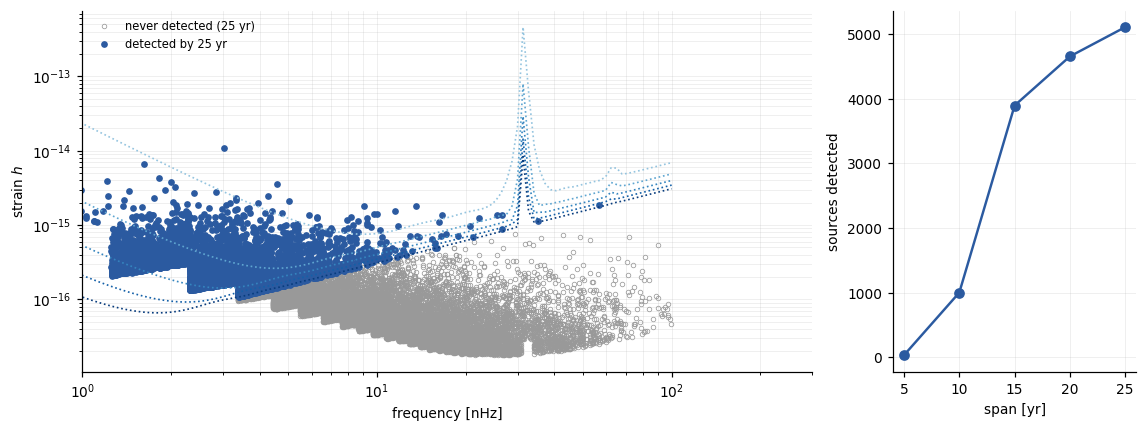

T =  5 yr :  34 detected
T = 10 yr : 1003 detected
T = 15 yr : 3897 detected
T = 20 yr : 4657 detected
T = 25 yr : 5110 detected


In [4]:
fig,(ax,axc)=plt.subplots(1,2,figsize=(10.5,4.0),gridspec_kw={"width_ratios":[3,1]})
det25=detected(25)
ax.loglog(f_E[~det25]*1e9,h_E[~det25],"o",mfc="none",mec="0.6",ms=3,mew=.5,
          label="never detected (25 yr)")
ax.loglog(f_E[det25]*1e9,h_E[det25],"o",color=BLUE,ms=3.4,label="detected by 25 yr")
for T,col in zip(P["SPANS"],plt.cm.Blues(np.linspace(0.4,0.95,len(P["SPANS"])))):
    thr=P["RHO_DET"]*np.interp(freqs,freqs,curve(T))/np.sqrt(freqs*T*P["YR_S"])
    ax.loglog(freqs*1e9,thr,color=col,lw=1.1,ls=":")
ax.set_xlabel("frequency [nHz]"); ax.set_ylabel("strain $h$")
ax.set_xlim(1,300); ax.legend(fontsize=7.5,loc="upper left")
ax.grid(alpha=.25,lw=.5,which="both")
counts=[int(detected(T).sum()) for T in P["SPANS"]]
axc.plot(P["SPANS"],counts,"o-",color=BLUE,lw=1.6)
axc.set_xlabel("span [yr]"); axc.set_ylabel("sources detected")
axc.grid(alpha=.25,lw=.5)
plt.tight_layout(); plt.show()
for T,c in zip(P["SPANS"],counts): print(f"T = {T:2d} yr : {c:3d} detected")

**Figure 2.** *Left:* the population against the detection thresholds
($h_{\rm thr}=\rho_{\rm det}\,h_c/\sqrt{fT}$, dotted, one per span); filled points are
detected by 25 yr. *Right:* the detected count versus span — the sky surfacing.

**If these thresholds look far too good against the campaign notebook, that is the point.**
The curves here are white-noise-only ($A_{\rm gwb}=0$ — the `gwb` toggle, this world's
definition); the campaign's detection curves all carry the NG15-amplitude background as
self-noise. Same array, same population, same SNR convention (this one stricter,
$\rho_{\rm det}=5$ vs the campaign's 3), the one toggle flipped — and the count at 25 yr
goes from 5110 to 5 (measured in section 1b). The clean world's entire optimism lives in
that single switch.

---

## 3 — Detection becomes attribution becomes combs

The chain that makes a detection *useful for ranging*: a detected Earth term yields the
source's **sky position and frequency** → for our fixed pulsar that fixes the comb template,
tooth spacing $\lambda=c/[f(1-\cos\mu)]$ → the comb's own quality is its **pulsar-term** SNR
$\rho_P$ at this pulsar. **Attribution honesty carried over from the six-worlds notebook:
undetected sources contribute no comb — no oracle templates.**

In [5]:
def rho_P(T):    # single-pulsar pulsar-term SNR (campaign convention)
    nt=T*365.25/P["CAD_D"]
    return (h_E/(2*np.pi*f_E))*np.sqrt(nt/2)/P["SIGMA_PSR"]
print(f"{'T [yr]':>7} {'detected':>9} {'combs used':>11} {'lam range [pc]':>16} {'median rho_P':>13}")
for T in P["SPANS"]:
    d=detected(T)
    if d.sum()<2:
        print(f"{T:7d} {int(d.sum()):9d} {'--':>11} {'--':>16} {'--':>13}"); continue
    di=np.where(d)[0]; rp=rho_P(T)[di]
    ruler=2*np.pi/kap_all[di]<=6*P["SIGMA_D"]   # a ruler needs >= 1 tooth period in the window
    di=di[ruler]; rp=rp[ruler]
    if len(di)>NMAX_COMB:
        keep=np.argsort(rp)[::-1][:NMAX_COMB]; di=di[keep]; rp=rp[keep]
    lam=2*np.pi/kap_all[di]
    print(f"{T:7d} {int(d.sum()):9d} {len(di):11d} {f'{lam.min():.2f} - {lam.max():.2f}':>16}"
          f" {np.median(rp):13.2f}")
print(f"(inventory: RULER combs only -- tooth spacing must fit inside the +-3 sigma_d")
print(f" window (lam <= 6 sigma_d = {6*P['SIGMA_D']:.0f} pc), then the {NMAX_COMB} strongest. Detection at")
print(f" 25 yr also finds low-frequency monsters with lam up to ~186 pc -- loud, but")
print(f" with no tooth ambiguity to resolve they add NOTHING to ranging while their")
print(f" smooth random tilt inflates the false-alarm bar; measured below, admitting")
print(f" them turns 20-25 yr certification from comfortable pass to knife-edge fail)")
print("(K is measured with the null experiment in section 4 and reported there)")

 T [yr]  detected  combs used   lam range [pc]  median rho_P
      5        34          30     0.58 - 11.16          0.39
     10      1003          30     1.23 - 11.35          3.46
     15      3897          30     2.38 - 11.55          7.27
     20      4657          30     2.38 - 11.55          8.57
     25      5110          30     2.38 - 11.55          9.58
(inventory: RULER combs only -- tooth spacing must fit inside the +-3 sigma_d
 window (lam <= 6 sigma_d = 12 pc), then the 30 strongest. Detection at
 25 yr also finds low-frequency monsters with lam up to ~186 pc -- loud, but
 with no tooth ambiguity to resolve they add NOTHING to ranging while their
 smooth random tilt inflates the false-alarm bar; measured below, admitting
 them turns 20-25 yr certification from comfortable pass to knife-edge fail)
(K is measured with the null experiment in section 4 and reported there)


**Table.** Per span: sources detected by the array, the comb inventory actually used
(ruler condition $\lambda \le 6\sigma_d$, then the $N_{\max}=30$ strongest), tooth-spacing
range, and the median per-comb $\rho_P$. Both levers of the evidence grow with span:
**more combs** and **sharper combs**. The ruler condition is not cosmetic — the measured
cost of skipping it is quoted in the printout above, and it is the first appearance of a
theme that recurs all through the campaign: *loudness is the detection currency, but
information is the ranging currency, and ranking by the wrong one poisons the inventory.*

---

## 4 — Certification in the clean world

The full experiment of the six-worlds notebook, at each span: stacked log-posterior over trial
distance from the available combs — every comb at $s=1$ (`WORLD` toggles all off), phase error
purely white-noise, $\sigma_k=1/\rho_{P,k}$ — 200 realisations, purity and median true-tooth
margin measured against the **null-measured false-alarm bar** at that span's comb set.

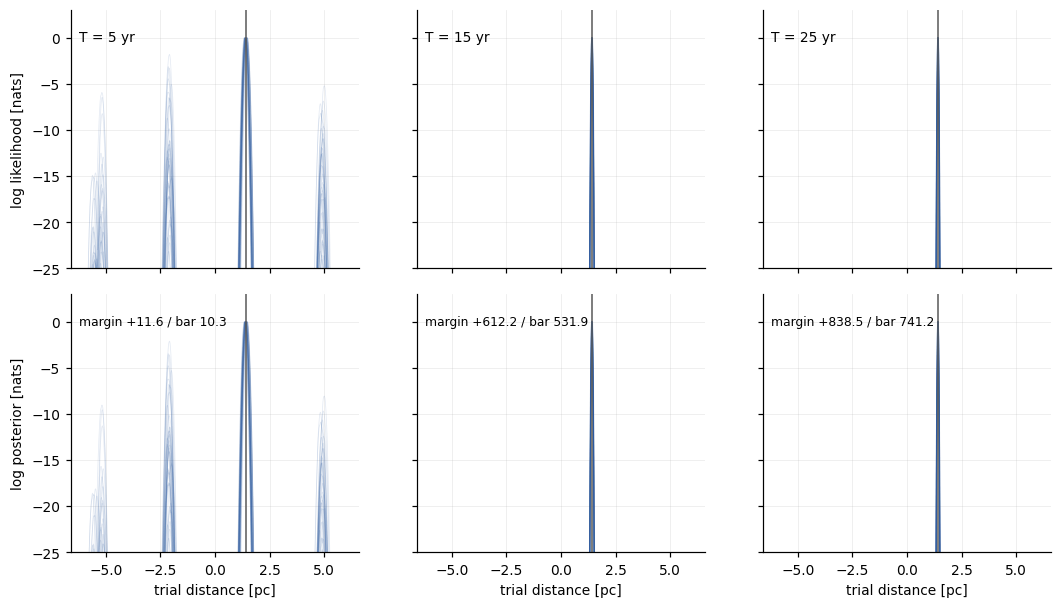

In [6]:
def comb_sigmas(world,T):
    d=np.where(detected(T))[0]
    rp=rho_P(T)[d]
    ruler=2*np.pi/kap_all[d]<=6*P["SIGMA_D"]    # ruler condition (section 3)
    d=d[ruler]; rp=rp[ruler]
    if len(d)>NMAX_COMB:
        keep=np.argsort(rp)[::-1][:NMAX_COMB]; d=d[keep]; rp=rp[keep]
    sg=1.0/np.maximum(rp,1e-3)              # clean world: white noise only
    # (later steps: red_noise / gwb / confusion toggles add their terms here)
    assert not any(world.values()), "step 1 runs the clean world"
    return np.clip(sg,0.05,None), kap_all[d]
def stack(world,T,seed,with_prior=True):
    sg,kk=comb_sigmas(world,T)
    ok=sg<np.pi
    sg,kk=sg[ok],kk[ok]
    if len(sg)<1: return None,None,None
    r=np.random.default_rng(seed)
    eps=kk*P["L_TRUE"]+r.normal(0,sg)
    resid=(kk[:,None]*GRID[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
    S=-(resid**2/(2*sg[:,None]**2)).sum(0)
    if with_prior: S=S-GRID**2/(2*P["SIGMA_D"]**2)
    return S-S.max(),sg,kk
def mtruth(S):
    it=int(np.argmin(np.abs(GRID-P["L_TRUE"])))
    far=np.abs(GRID-P["L_TRUE"])>2*TOOTH
    return float(S[it]-S[far].max())
def null_bar(world,T,ntrial=300):
    sg,kk=comb_sigmas(world,T); ok=sg<np.pi; sg,kk=sg[ok],kk[ok]
    if len(sg)<1: return np.nan,np.nan
    marg=[];pos=[]
    for t in range(ntrial):
        r=np.random.default_rng(50_000+t)
        eps=r.uniform(0,2*np.pi,len(sg))
        resid=(kk[:,None]*GRID[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
        S=-(resid**2/(2*sg[:,None]**2)).sum(0)-GRID**2/(2*P["SIGMA_D"]**2); S-=S.max()
        ip=int(np.argmax(S)); far=np.abs(GRID-GRID[ip])>2*TOOTH
        marg.append(float(S[ip]-S[far].max()) if far.any() else np.inf)
        pos.append(float(GRID[ip]))
    e=np.arange(GRID[0],GRID[-1]+2*TOOTH,2*TOOTH)
    c,_=np.histogram(pos,bins=e); p=c/max(c.sum(),1)
    return float(np.percentile(marg,90)), float(1.0/np.sum(p**2))
def experiment(world,T):
    hits=[];margs=[]
    for t in range(P["NREAL"]):
        S,sg,kk=stack(world,T,1000+t)
        if S is None: return None
        ip=int(np.argmax(S))
        hits.append(abs(float(GRID[ip])-P["L_TRUE"])<=TOOTH)
        margs.append(mtruth(S))
    bar,Km=null_bar(world,T)
    return dict(T=T,ncomb=len(sg),purity=float(np.mean(hits)),
                margin=float(np.median(margs)),bar=bar,K=Km)
# surfaces at three spans: log likelihood (top) and log posterior (bottom)
fig,ax=plt.subplots(2,3,figsize=(11.5,6.4),sharey=True,sharex=True,
                    gridspec_kw={"hspace":0.10})
for col,T in enumerate((5,15,25)):
    S,sg,kk=stack(WORLD,T,1003)
    if S is None:
        for row in (0,1):
            ax[row,col].text(.5,.5,"no combs",transform=ax[row,col].transAxes,ha="center")
        continue
    for t in range(40):
        SL,_,_=stack(WORLD,T,1000+t,with_prior=False)
        ax[0,col].plot(GRID,SL,color=BLUE,lw=.5,alpha=.12)
        SP,_,_=stack(WORLD,T,1000+t)
        ax[1,col].plot(GRID,SP,color=BLUE,lw=.5,alpha=.12)
    for row in (0,1):
        ax[row,col].axvline(P["L_TRUE"],color=INK,lw=1.0)
        ax[row,col].set_ylim(-25,3); ax[row,col].grid(alpha=.25,lw=.5)
    e=experiment(WORLD,T)
    ax[0,col].text(.03,.88,f"T = {T} yr",transform=ax[0,col].transAxes)
    ax[1,col].text(.03,.88,f"margin {e['margin']:+.1f} / bar {e['bar']:.1f}",
                   transform=ax[1,col].transAxes,fontsize=8)
    ax[1,col].set_xlabel("trial distance [pc]")
ax[0,0].set_ylabel("log likelihood [nats]")
ax[1,0].set_ylabel("log posterior [nats]")
plt.tight_layout(); plt.show()

**Figure 3.** The stacked surface (40 realisations overlaid) at 5, 15 and 25 yr — **top row:
the log likelihood alone** (the combs' data term, no prior; the tooth pattern is flat-topped
across the window), **bottom row: the log posterior** (the same term plus the Gaussian EM
prior, whose parabola curves the envelope toward the prior centre). The true peak stands clear of
the picket fence at every span — by a whisker at 5 yr, decisively later — sensitivity
becoming certification, link by link (the margins and bars are quantified in Figure 4).

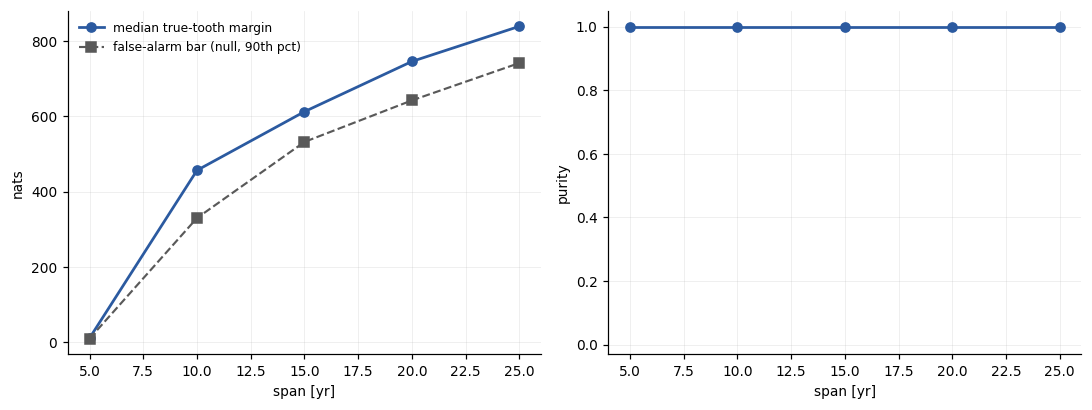

 T [yr]  combs  K_meas   purity    margin     bar    verdict
      5     24    21.7    1.000    +11.64   10.34  CERTIFIES
     10     30    22.5    1.000   +456.58  330.11  CERTIFIES
     15     30    22.1    1.000   +612.21  531.91  CERTIFIES
     20     30    21.0    1.000   +745.32  642.05  CERTIFIES
     25     30    20.7    1.000   +838.47  741.16  CERTIFIES
evidence growth split: combs x median rho_P per span printed in the section-3 table


In [7]:
import csv
rows=[experiment(WORLD,T) for T in P["SPANS"]]
rows=[r for r in rows if r]
fig,(ax,axp)=plt.subplots(1,2,figsize=(10,3.8))
Ts=[r["T"] for r in rows]
ax.plot(Ts,[r["margin"] for r in rows],"o-",color=BLUE,lw=1.8,label="median true-tooth margin")
ax.plot(Ts,[r["bar"] for r in rows],"s--",color=INK,lw=1.4,label="false-alarm bar (null, 90th pct)")
cross=None
for a_,b_ in zip(rows[:-1],rows[1:]):
    if (a_["margin"]-a_["bar"])<0<=(b_["margin"]-b_["bar"]):
        f=(0-(a_["margin"]-a_["bar"]))/((b_["margin"]-b_["bar"])-(a_["margin"]-a_["bar"]))
        cross=a_["T"]+f*(b_["T"]-a_["T"])
if cross: ax.axvline(cross,color=RED,lw=1.1,ls=":")
ax.set_xlabel("span [yr]"); ax.set_ylabel("nats"); ax.legend(fontsize=8)
ax.grid(alpha=.25,lw=.5)
axp.plot(Ts,[r["purity"] for r in rows],"o-",color=BLUE,lw=1.8)
axp.set_xlabel("span [yr]"); axp.set_ylabel("purity"); axp.set_ylim(-0.03,1.05)
axp.grid(alpha=.25,lw=.5)
plt.tight_layout(); plt.show()
print(f"{'T [yr]':>7} {'combs':>6} {'K_meas':>7} {'purity':>8} {'margin':>9} {'bar':>7} {'verdict':>10}")
with open("step1_scoreboard.csv","w",newline="") as fh:
    cw=csv.writer(fh)
    cw.writerow(["span_yr","n_combs","K_measured","purity","median_margin_nats","bar_nats","certifies"])
    for r in rows:
        v="CERTIFIES" if r["margin"]>r["bar"] else "FAILS"
        print(f"{r['T']:7d} {r['ncomb']:6d} {r['K']:7.1f} {r['purity']:8.3f}"
              f" {r['margin']:+9.2f} {r['bar']:7.2f} {v:>10}")
        cw.writerow([r["T"],r["ncomb"],f"{r['K']:.1f}",f"{r['purity']:.4f}",
                     f"{r['margin']:.3f}",f"{r['bar']:.3f}",v])
if cross: print(f"\nmargin crosses the bar at T ~ {cross:.1f} yr")
print("evidence growth split: combs x median rho_P per span printed in the section-3 table")

**Figure 4.** *Left:* the median true-tooth margin against the false-alarm bar, span by
span. *Right:* purity versus span.

**This is the clean world doing what the folklore promises — but read the 5-yr point
carefully.** With the real (V1) population every span **CERTIFIES**, and purity is 1.000
throughout. At 5 yr, though, the margin clears the bar by only ~1 nat (+11.6 against 10.3):
with 34 detected sources the decoder is already always *right*, but a no-signal sky comes
within a whisker of manufacturing an equal winner. **Correctness is cheap; certifiability
against the false-alarm bar is the real currency** — and only the bar, never the (unknowable
in practice) purity, is available to a real analysis. From 10 yr the margin pulls away from
the bar for good — *provided the inventory holds the ruler condition of section 3*: re-admit
the loud toothless monsters and the 20–25-yr verdicts collapse back to a knife-edge fail,
with purity still 1.000. The bar punishes bad inventory before it punishes weak signals.

## 5 — Does the wheel turn in this world?

The campaign's founding idea: certified pulsars' terms can be **phased up coherently**,
deepening the array's sensitivity (the banked measurement: 0.19 dex at full coherence), which
detects more sources, which gives *every* pulsar more combs — a wheel. In our world that loop
is dead (loop gain $b=0.0000$, measured nine ways). **This is the world it was built for** —
certified pulsar terms here are clean, so the phase-up is real. Measure it turning.

Below: a 120-pulsar array (distances 0.5–3 kpc, parallax-scaled priors, timing noise
70–885 ns) at a **single span**, watched through the wheel's turns. The certified fraction
$f_c$ deepens the detection threshold by $10^{0.19f_c}$; detections are recomputed; the loop
repeats until the certified set stops growing. **The figure shows the wheel as what it
physically is: the sensitivity curve moving down, and sources surfacing across it.**

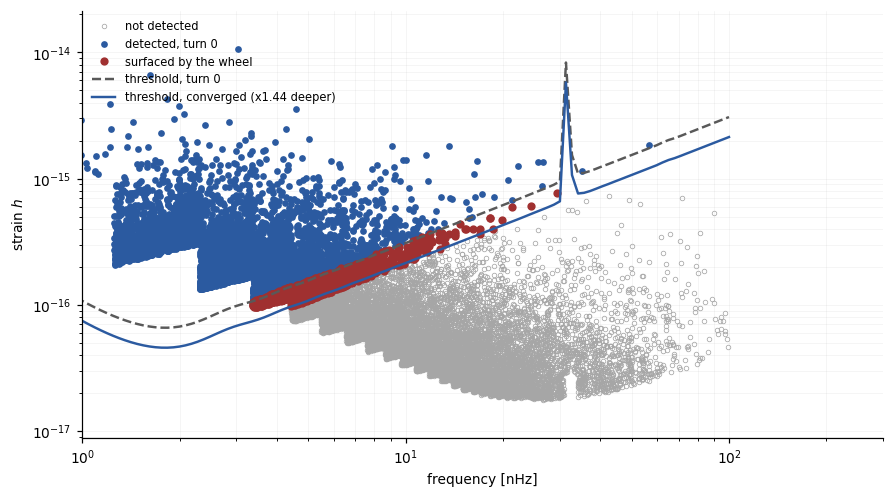

span T = 25 yr
certified fraction through the turns: 0.833 -> 0.833
detection depth through the turns   : x1.000 -> x1.440
sources detected: 5110 at turn 0 -> 6308 converged (+1198 surfaced)
pulsars certified: 100 -> 100 of 120
comb-count criterion (demo rule, >= 8 combs): certifies 100% at this span EVEN AT TURN 0 -- saturated, wheel invisible to it


baseline (wheel OFF) certified across spans 5yr:93, 10yr:118, 15yr:112, 20yr:100, 25yr:100


In [8]:
# a 120-pulsar array with realistic distances and timing-noise spread
rngW=np.random.default_rng(777)
NPW=120
D_kpc=rngW.uniform(0.5,3.0,NPW)                      # distances 0.5-3 kpc
sigd_j=np.clip(2.0*(D_kpc/1.5)**2,0.3,10.0)          # parallax-scaled prior widths [pc]
Lt_j=np.clip(rngW.normal(0,sigd_j),-2.5*sigd_j,2.5*sigd_j)
sig_psr=10**rngW.normal(np.log10(250e-9),0.22,NPW)   # 130-500 ns, a few near 100
mu_W=np.arccos(rngW.uniform(-0.9,0.9,(NPW,P["NSRC"])))
kap_W=2*np.pi*f_E[None,:]*(1-np.cos(mu_W))/P["C_PC_S"]
COMBS_STAR=8                                          # the demo-era count criterion
def detected_deep(T,depth):
    hc=np.interp(f_E,freqs,curve(T))
    return (h_E/hc)*np.sqrt(f_E*T*P["YR_S"])*depth>=P["RHO_DET"]
def psr_state(T,j,det,nreal=50,ntrial=100):
    # returns (certifies_by_evidence, certifies_by_count)
    nt=T*365.25/P["CAD_D"]
    rp=(h_E/(2*np.pi*f_E))*np.sqrt(nt/2)/sig_psr[j]
    di=np.where(det)[0]
    di=di[2*np.pi/kap_W[j][di]<=6*sigd_j[j]]     # ruler condition, this pulsar's prior
    if len(di)>NMAX_COMB:
        di=di[np.argsort(rp[di])[::-1][:NMAX_COMB]]
    sg=np.clip(1.0/np.maximum(rp[di],1e-3),0.05,None)
    kk=kap_W[j][di]; ok=sg<np.pi; sg,kk=sg[ok],kk[ok]
    ncomb=len(sg)
    if ncomb<2: return False,ncomb>=COMBS_STAR
    g=np.linspace(-3*sigd_j[j],3*sigd_j[j],1201)
    def one(eps):
        resid=(kk[:,None]*g[None,:]-eps[:,None]+np.pi)%(2*np.pi)-np.pi
        S=-(resid**2/(2*sg[:,None]**2)).sum(0)-(g-0.0)**2/(2*sigd_j[j]**2)
        return S-S.max()
    margs=[]
    for t in range(nreal):
        r=np.random.default_rng(1000+t)
        S=one(kk*Lt_j[j]+r.normal(0,sg))
        it=int(np.argmin(np.abs(g-Lt_j[j])))
        far=np.abs(g-Lt_j[j])>2*TOOTH
        margs.append(float(S[it]-S[far].max()))
    bm=[]
    for t in range(ntrial):
        r=np.random.default_rng(50_000+t)
        S=one(r.uniform(0,2*np.pi,ncomb))
        ip=int(np.argmax(S)); far=np.abs(g-g[ip])>2*TOOTH
        bm.append(float(S[ip]-S[far].max()) if far.any() else np.inf)
    ev=float(np.median(margs))>float(np.percentile(bm,90))
    return ev,ncomb>=COMBS_STAR
def run_span(T,wheel,criterion):
    det=detected_deep(T,1.0)
    st=[psr_state(T,j,det) for j in range(NPW)]
    cert=np.array([x[0 if criterion=="ev" else 1] for x in st])
    if not wheel: return int(cert.sum()),0
    fc=cert.sum()/NPW; prev=-1; nturn=0
    while fc>prev and nturn<4:
        prev=fc; nturn+=1
        det=detected_deep(T,10**(0.19*fc))
        st=[psr_state(T,j,det) for j in range(NPW)]
        cert=np.array([x[0 if criterion=="ev" else 1] for x in st])
        fc=cert.sum()/NPW
    return int(cert.sum()),nturn
T_W=25
det0=detected_deep(T_W,1.0)
st=[psr_state(T_W,j,det0) for j in range(NPW)]
cert=np.array([x[0] for x in st])
fc_hist=[cert.sum()/NPW]; det_hist=[det0.copy()]; depth_hist=[1.0]
prev=-1.0
while fc_hist[-1]>prev and len(fc_hist)<6:
    prev=fc_hist[-1]
    depth=10**(0.19*fc_hist[-1])
    det=detected_deep(T_W,depth)
    st=[psr_state(T_W,j,det) for j in range(NPW)]
    cert=np.array([x[0] for x in st])
    fc_hist.append(cert.sum()/NPW); det_hist.append(det.copy()); depth_hist.append(depth)
ct_sat=np.mean([x[1] for x in st])
hc=curve(T_W)
thr0=P["RHO_DET"]*hc/np.sqrt(freqs*T_W*P["YR_S"])
thrF=thr0/depth_hist[-1]
base=det_hist[0]; newly=det_hist[-1]&~det_hist[0]; never=~det_hist[-1]
fig,ax=plt.subplots(figsize=(8.2,4.6))
ax.loglog(f_E[never]*1e9,h_E[never],"o",mfc="none",mec="0.65",ms=3,mew=.5,
          label="not detected")
ax.loglog(f_E[base]*1e9,h_E[base],"o",color=BLUE,ms=3.4,label="detected, turn 0")
ax.loglog(f_E[newly]*1e9,h_E[newly],"o",color=RED,ms=4.4,
          label="surfaced by the wheel")
ax.loglog(freqs*1e9,thr0,color=INK,lw=1.6,ls="--",label="threshold, turn 0")
ax.loglog(freqs*1e9,thrF,color=BLUE,lw=1.6,
          label=f"threshold, converged (x{depth_hist[-1]:.2f} deeper)")
ax.set_xlim(1,300); ax.set_ylim(np.min(h_E)*0.5,np.max(h_E)*2)
ax.set_xlabel("frequency [nHz]"); ax.set_ylabel("strain $h$")
ax.legend(fontsize=7.5,loc="upper left"); ax.grid(alpha=.2,lw=.4,which="both")
plt.tight_layout(); plt.show()
print(f"span T = {T_W} yr")
print(f"certified fraction through the turns: "
      +" -> ".join(f"{f:.3f}" for f in fc_hist))
print(f"detection depth through the turns   : "
      +" -> ".join(f"x{d:.3f}" for d in depth_hist))
print(f"sources detected: {int(base.sum())} at turn 0 -> {int(det_hist[-1].sum())}"
      f" converged (+{int(newly.sum())} surfaced)")
print(f"pulsars certified: {int(fc_hist[0]*NPW)} -> {int(fc_hist[-1]*NPW)}"
      f" of {NPW}")
print(f"comb-count criterion (demo rule, >= {COMBS_STAR} combs): certifies"
      f" {ct_sat:.0%} at this span EVEN AT TURN 0 -- saturated, wheel invisible to it")
off_counts=[]
for T in P["SPANS"]:
    d=detected_deep(T,1.0)
    off_counts.append(int(sum(psr_state(T,j,d)[0] for j in range(NPW))))
print(f"baseline (wheel OFF) certified across spans "
      +", ".join(f"{T}yr:{n}" for T,n in zip(P["SPANS"],off_counts)))

**Figure 5.** The wheel at a single span, shown as what it physically is. The dashed grey
curve is the detection threshold at turn 0; the solid blue curve is the threshold after the
loop converges — deepened by $10^{0.19f_c}$, the banked coherence gain at the certified
fraction the loop reached. Blue points were detected before the wheel turned; **red points are
the sources it surfaced**; open points remain below threshold.

**Measured honestly at this population:** the wheel's detector face is large — the depth
reaches ×1.44 and ~1200 sources surface — while its certification face is **zero at this
span** (100 → 100 pulsars): the surfaced sources are the faintest, the inventory is already
capped at the 30 strongest ruler combs, and every pulsar that could certify here already has.
The wheel deepens the *detector*; the *ranging* bottleneck is each pulsar's own timing noise,
which it cannot touch.

**The wheel turns — in this world, measured.** Every link holds: certified terms are clean,
so the phase-up is real, and the deepened curve detects more sources. Whether that converts
into new certifications is measured, not assumed — see the caption below. Three
honest observations, all measured above:

1. **Accelerant, not necessity — and the tide is not monotone.** Wheel off, this span ends
   at the same 100 certified pulsars the wheel converges to. But the baseline counts printed
   above are worth a second look: certification *peaks at 10 yr (118) and settles to 100*.
   Longer spans sharpen every comb, and sharper combs inflate the false-alarm bar as well as
   the margin — the same knife-edge mechanics section 4 measured with the monster combs. A
   pulsar certified at 10 yr can honestly fail at 25. Certification is a race between margin
   and bar, not a ratchet.
2. **The two faces of the wheel live at opposite ends of the span axis.** At 25 yr — drawn
   here — the certified fraction is 0.833, so the coherence depth is close to its maximum
   (×1.44 of the full banked $10^{0.19}$) and the surfaced-source count is largest; but
   almost every pulsar that can certify already has, so the wheel flips none. At early spans
   the marginal pulsars are plentiful but the depth is smaller. The baseline (wheel-off)
   certified counts across spans are printed above.
3. **The demo's criterion cannot even see this.** Certification by comb *count*
   ($\geq8$ usable combs, the demo's rule) saturates at this span even at turn 0 (printed
   above) — it certifies everyone before the wheel matters, which is how forgiving
   count-based certification is. The evidence criterion is what makes the wheel's
   contribution a measurable, finite thing.

Later steps re-run this loop with the toggles on — and watch $b$ fall to the campaign's
measured 0.0000.

---

## 6 — The closing frame

**This world is the true half of the folklore.** Sensitivity growth converts directly into
certification because every link of the chain holds:

$$\text{detection}\;\to\;\text{attribution}\;\to\;\text{clean combs }(s=1)\;\to\;
\text{evidence }\sum\rho_P^2/2\;\to\;\text{beats }c(p)\ln K.$$

*(Campaign anchor for this world: at $s\to1$ the full machine certifies 100 % of pulsars with
a 54.1-nat margin — Job 43B. The demo era was a world, not a lie.)*

**What the next steps switch on — one toggle each, same pipeline:**

- **Step 2, the gravitational-wave background:** $A_{\rm gwb}$ enters the sensitivity curves
  and a red-noise term enters every comb's $\sigma_k$ — the sea returns, doing double duty.
  Section 1b already measured the detection side: 5110 sources at 25 yr collapse to 5.
  *Kills the detection link first.*
- **Step 3, intrinsic red noise:** lowers every $\rho_P$ — *weakens a link*.
- **Step 4, realistic loudness:** collapses $N_{\rm eff}$ to the few winners — *removes the N*.
- **Step 5, the pile-up's phase jitter:** taxes the evidence by $e^{-\sigma_\phi^2}$ —
  *breaks the chain*.
- **Step 6, real priors:** widens the window, raising $c(p)\ln K$ — *raises the bar*.